1.Import torchvision

In [23]:
import torch
import torchvision
from torchvision.transforms import v2

2. load, Preprocess, and normalize the data and divide the training to 4 batches

In [24]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 4

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

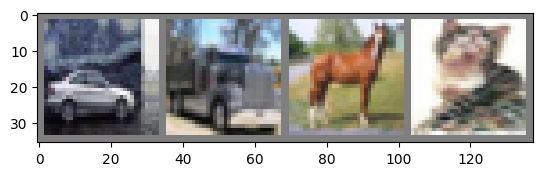

car   truck horse cat  


In [25]:
#some of the training images
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image


def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))
# print labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

3. Define the CNN architecture

In [26]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.conv3 = nn.Conv2d(16, 32, 3)

        self.fc1 = nn.Linear(32 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = F.relu(self.conv2(x))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x


net = Net()

4. Define the loss function and optimizer


In [27]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

5. Train the CNN

In [46]:
# Store metrics
train_losses = []
train_accuracies = []

for epoch in range(2):  # loop over the dataset multiple times

    running_loss = 0.0
    correct = 0
    total = 0

    for i, data in enumerate(trainloader, 0):

        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        if i % 2000 == 1999:
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 2000:.3f}')
            running_loss = 0.0

    # Save metrics after each epoch
    train_losses.append(running_loss / len(trainloader))
    train_accuracies.append(100 * correct / total)

print('Finished Training')

[1,  2000] loss: 1.307
[1,  4000] loss: 1.310
[1,  6000] loss: 1.310
[1,  8000] loss: 1.316
[1, 10000] loss: 1.318
[1, 12000] loss: 1.330
[2,  2000] loss: 1.327
[2,  4000] loss: 1.311
[2,  6000] loss: 1.308
[2,  8000] loss: 1.311
[2, 10000] loss: 1.325
[2, 12000] loss: 1.312
Finished Training


A. Visualize the learned filters

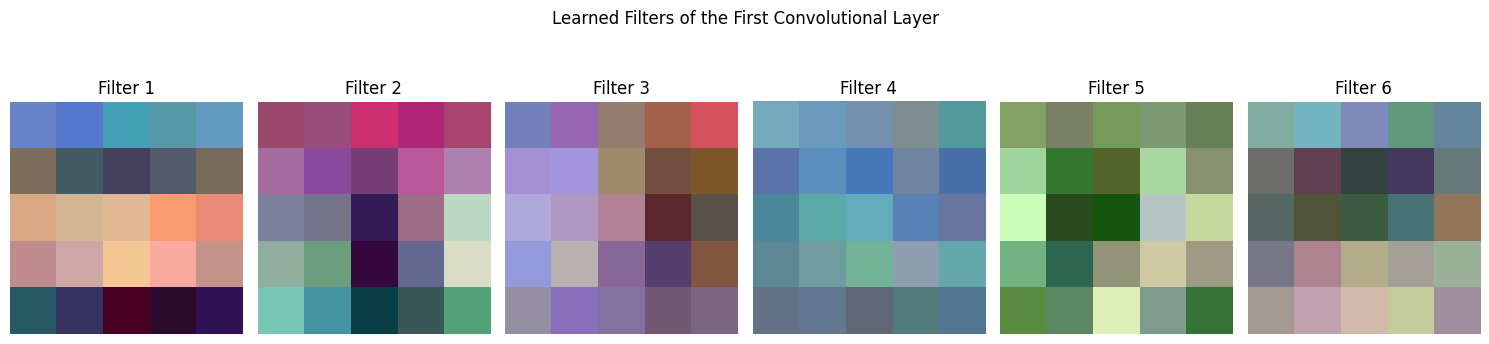

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Get the learned weights from the first convolutional layer
filters = net.conv1.weight.data.clone()

# Move filters to CPU (if using GPU)
filters = filters.cpu()

# Normalize filters for visualization
filters = (filters - filters.min()) / (filters.max() - filters.min())

# Create a figure
fig, axes = plt.subplots(1, 6, figsize=(15, 4))

for i in range(6):
    # Get the i-th filter
    filter_img = filters[i]

    # Change dimensions from (C, H, W) to (H, W, C)
    filter_img = np.transpose(filter_img.numpy(), (1, 2, 0))

    axes[i].imshow(filter_img)
    axes[i].set_title(f'Filter {i+1}')
    axes[i].axis('off')

plt.suptitle('Learned Filters of the First Convolutional Layer')
plt.tight_layout()
plt.show()

7. Save the trained model


In [29]:
PATH = './cifar_net.pt'
torch.save(net.state_dict(), PATH)

8. Evaluate and test the model


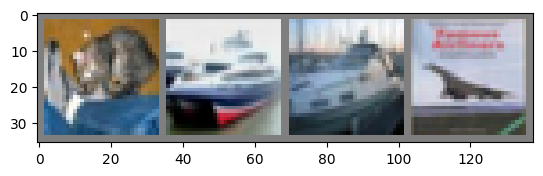

GroundTruth:  cat   ship  ship  plane


In [30]:
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

load back in our saved model

In [31]:
net = Net()
net.load_state_dict(torch.load(PATH, weights_only=True))

<All keys matched successfully>

 let us see what the neural network thinks these examples above are:

In [32]:
outputs = net(images)

The outputs are energies for the 10 classes. The higher the energy for a class, the more the network thinks that the image is of the particular class. So, let’s get the index of the highest energy:

In [33]:
_, predicted = torch.max(outputs, 1)

print('Predicted: ', ' '.join(f'{classes[predicted[j]]:5s}'
                              for j in range(4)))

Predicted:  cat   ship  ship  ship 


how the network performs on the whole dataset

In [34]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 50 %


That looks way better than chance, which is 10% accuracy (randomly picking a class out of 10 classes). Seems like the network learnt something.

Hmmm, what are the classes that performed well, and the classes that did not perform well:

In [35]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in testloader:
        images, labels = data
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 45.5 %
Accuracy for class: car   is 52.4 %
Accuracy for class: bird  is 47.2 %
Accuracy for class: cat   is 48.8 %
Accuracy for class: deer  is 25.1 %
Accuracy for class: dog   is 27.2 %
Accuracy for class: frog  is 69.1 %
Accuracy for class: horse is 45.2 %
Accuracy for class: ship  is 75.2 %
Accuracy for class: truck is 68.9 %


In [44]:
class BadNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Incorrectly increase stride
        self.conv1 = nn.Conv2d(3, 6, 5, stride=2)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5, stride=2)
        self.conv3 = nn.Conv2d(16, 32, 3)

        self.fc1 = nn.Linear(32 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        print("Input:", x.shape)

        x = self.pool(F.relu(self.conv1(x)))
        print("After Conv1 + Pool:", x.shape)

        x = F.relu(self.conv2(x))
        print("After Conv2:", x.shape)

        x = self.pool(F.relu(self.conv3(x)))
        print("After Conv3 + Pool:", x.shape)

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x


bad_net = BadNet()

# Try one batch
images, labels = next(iter(trainloader))

outputs = bad_net(images)

Input: torch.Size([4, 3, 32, 32])
After Conv1 + Pool: torch.Size([4, 6, 7, 7])
After Conv2: torch.Size([4, 16, 2, 2])


RuntimeError: Calculated padded input size per channel: (2 x 2). Kernel size: (3 x 3). Kernel size can't be greater than actual input size

Increasing the stride of the first and second convolutional layers caused the feature maps to shrink aggressively from 32×32 to 7×7 and then to 2×2. This resulted in a runtime error in the third convolutional layer because its 3×3 kernel was larger than the available 2×2 input. The experiment demonstrates the importance of selecting appropriate stride and padding values to preserve sufficient spatial dimensions throughout the CNN.

• Plot train and validation loss and accuracy per epoch.


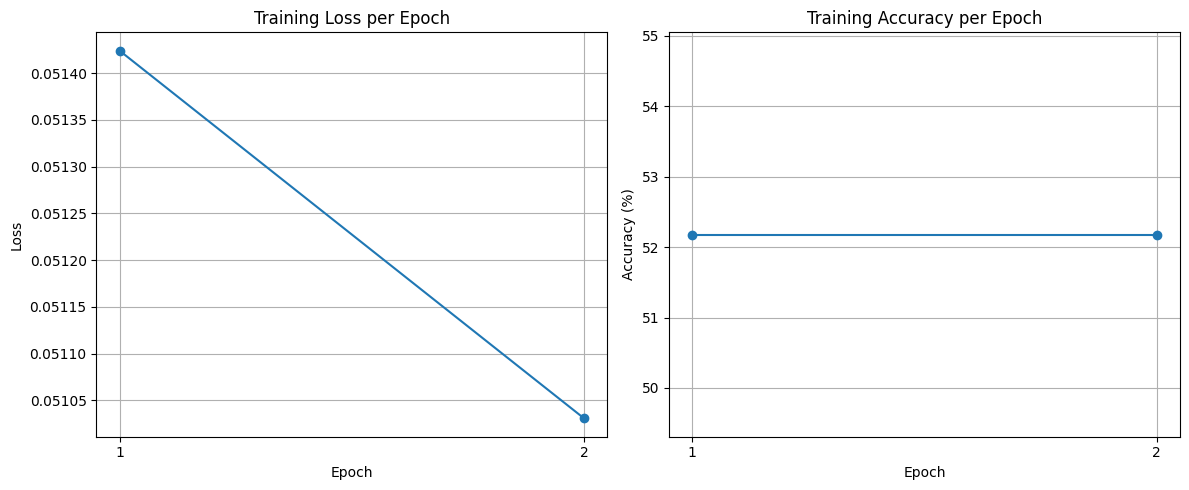

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, 3), train_losses, marker='o')
plt.title('Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks([1, 2])
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(range(1, 3), train_accuracies, marker='o')
plt.title('Training Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks([1, 2])
plt.grid()

plt.tight_layout()
plt.show()